# Learning-order analysis — nine paired seeds

Reads 27 frozen runs (9 seeds × 3 curricula), computes paired comparisons, and generates figures. No training.

In [2]:
import csv
import json
import math
import statistics
from pathlib import Path
import matplotlib.pyplot as plt

PROJECT_ROOT = Path().cwd().parent.parent
EXPERIMENT_DIR = PROJECT_ROOT / "outputs" / "small_world" / "experiments" / "learning_order"
RESULT_PATH = EXPERIMENT_DIR / "schedule_comparison.json"
OUTPUT_DIR = EXPERIMENT_DIR

with RESULT_PATH.open(encoding="utf-8") as stream:
    experiment = json.load(stream)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Result:", RESULT_PATH)
print("Seeds:", experiment["config"]["seeds"])
print("Saved figures and tables:", OUTPUT_DIR)

Result: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\small_world\experiments\learning_order\schedule_comparison.json
Seeds: [42, 43, 44, 45, 46, 47, 48, 49, 50]
Saved figures and tables: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\small_world\experiments\learning_order


## 1. Check recorded runs

Verify all 27 runs use comparable update and exposure budgets.

In [3]:
SEEDS = sorted(experiment["config"]["seeds"])
SCHEDULES = ("mixed", "staged", "reverse")
TASKS = ("color", "shape", "pair")
RUNS = {(run["seed"], run["schedule"]): run for run in experiment["runs"]}
assert len(RUNS) == len(SEEDS) * len(SCHEDULES)
for seed in SEEDS:
    seed_runs = [RUNS[(seed, name)] for name in SCHEDULES]
    assert len({run["steps_run"] for run in seed_runs}) == 1
    assert len({run["exposure_plan"]["repetitions_per_example"] for run in seed_runs}) == 1
    assert len({run["exposure_plan"]["examples"] for run in seed_runs}) == 1
    assert len({run["final"]["id_dev"]["n"] for run in seed_runs if "n" in run["final"]["id_dev"]}) <= 1
print(f"Validated {len(RUNS)} runs, {len(SEEDS)} paired seeds, {seed_runs[0]['steps_run']} updates per model")
print("Frozen manifests:", experiment["dataset_hashes"])
print("Environment:", experiment["environment"])

Validated 27 runs, 9 paired seeds, 450 updates per model
Frozen manifests: {'train.jsonl': '49887fa41e1d31eaaea18b9c56d5a8f238e2cf05a8aef9e66418a4fee805c89b', 'id_dev.jsonl': 'bcb98cdac003c62da68b3829459a737ab8c6d9a8d60bdc29e87ee4b5a63692c9'}
Environment: {'torch': '2.13.0+cu130', 'cuda_build': '13.0', 'cuda_available': True, 'num_threads': 4, 'device_name': 'NVIDIA GeForce RTX 5050 Laptop GPU', 'capability': [12, 0]}


## 2. Summarize accuracy

Reports accuracy and loss for each schedule and seed.

In [4]:
records = []
for seed in SEEDS:
    for schedule in SCHEDULES:
        dev = RUNS[(seed, schedule)]["final"]["id_dev"]
        record = {"seed": seed, "schedule": schedule,
                  "overall_pct": 100 * dev["accuracy"], "cross_entropy": dev["loss"],
                  "swap_flip_pct": 100 * RUNS[(seed, schedule)]["paired_counterfactual"]["prediction_flip_rate"]}
        record.update({f"{task}_pct": 100 * dev["by_template"][task] for task in TASKS})
        records.append(record)
with (OUTPUT_DIR / "accuracy_by_seed.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)
for schedule in SCHEDULES:
    subset = [r for r in records if r["schedule"] == schedule]
    values = [r["pair_pct"] for r in subset]
    overall = [r["overall_pct"] for r in subset]
    print(f"{schedule:8s} binding={statistics.mean(values):5.1f}% ± {statistics.stdev(values):4.1f} pp; overall={statistics.mean(overall):5.1f}%")

mixed    binding= 69.7% ±  5.1 pp; overall= 79.9%
staged   binding= 71.9% ±  9.2 pp; overall= 79.8%
reverse  binding= 65.3% ±  9.1 pp; overall= 78.0%


## 3. Compare schedules

Measures paired differences in binding accuracy across seeds.

In [5]:
from scipy.stats import t
differences = []
for seed in SEEDS:
    binding = {schedule: 100 * RUNS[(seed, schedule)]["final"]["id_dev"]["by_template"]["pair"]
               for schedule in SCHEDULES}
    differences.append({"seed": seed, "staged_minus_mixed_pp": binding["staged"] - binding["mixed"],
                        "staged_minus_reverse_pp": binding["staged"] - binding["reverse"],
                        "mixed_minus_reverse_pp": binding["mixed"] - binding["reverse"]})
with (OUTPUT_DIR / "paired_differences.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(differences[0]))
    writer.writeheader()
    writer.writerows(differences)
for field in ("staged_minus_mixed_pp", "staged_minus_reverse_pp", "mixed_minus_reverse_pp"):
    values = [r[field] for r in differences]
    mean = statistics.mean(values)
    sd = statistics.stdev(values)
    # Student's t interval for paired seeds: df = len(SEEDS) - 1 = 8.
    margin = t.ppf(0.975, df=len(SEEDS)-1) * sd / math.sqrt(len(SEEDS))
    print(f"{field}: differences={[round(v, 2) for v in values]}; mean={mean:+.2f} pp; approximate 95% CI=[{mean-margin:+.2f}, {mean+margin:+.2f}] pp")

staged_minus_mixed_pp: differences=[10.0, 15.0, 5.0, 0.0, -7.5, -5.0, -17.5, 5.0, 15.0]; mean=+2.22 pp; approximate 95% CI=[-6.12, +10.57] pp
staged_minus_reverse_pp: differences=[5.0, 7.5, 20.0, 12.5, 10.0, -2.5, -2.5, -12.5, 22.5]; mean=+6.67 pp; approximate 95% CI=[-1.98, +15.31] pp
mixed_minus_reverse_pp: differences=[-5.0, -7.5, 15.0, 12.5, 17.5, 2.5, 15.0, -17.5, 7.5]; mean=+4.44 pp; approximate 95% CI=[-4.91, +13.80] pp


## 4. Plot binding accuracy across nine seeds

Colored dots are individual seeds; black diamonds and error bars indicate mean ± sample standard deviation, not a confidence interval.

mixed: mean=69.72%, sample SD=5.07 pp (n=9)
staged: mean=71.94%, sample SD=9.17 pp (n=9)
reverse: mean=65.28%, sample SD=9.14 pp (n=9)


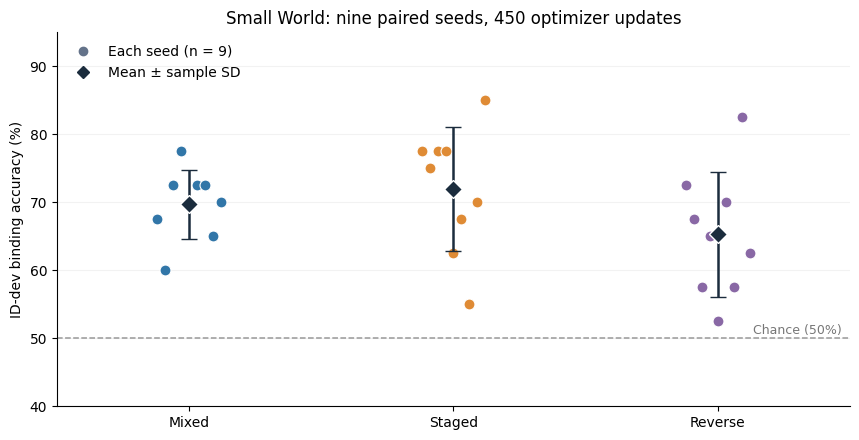

In [6]:
import numpy as np
# Figure 1 in Submission II: nine actual paired seeds, not one run per schedule.
from matplotlib.lines import Line2D

seed_colors = {'mixed': '#3176A8', 'staged': '#DF8B35', 'reverse': '#8968A5'}
fig, ax = plt.subplots(figsize=(8.7, 4.5))
for i, schedule in enumerate(SCHEDULES):
    values = np.array([100 * RUNS[(seed, schedule)]['final']['id_dev']['by_template']['pair']
                       for seed in SEEDS])
    positions = i + (np.arange(len(SEEDS)) - (len(SEEDS) - 1) / 2) * 0.03
    ax.scatter(positions, values, s=62, color=seed_colors[schedule], edgecolors='white',
               linewidth=0.8, zorder=3)
    mean, sd = values.mean(), values.std(ddof=1)
    ax.errorbar(i, mean, yerr=sd, fmt='D', ms=9, mfc='#1B2C3D', mec='white',
                ecolor='#1B2C3D', capsize=6, linewidth=1.8, zorder=7)
    print(f'{schedule}: mean={mean:.2f}%, sample SD={sd:.2f} pp (n={len(SEEDS)})')
ax.set(xlim=(-0.5, 2.5), ylim=(40, 95), ylabel='ID-dev binding accuracy (%)',
       title='Small World: nine paired seeds, 450 optimizer updates')
ax.set_xticks(range(3), ['Mixed', 'Staged', 'Reverse'])
ax.axhline(50, ls='--', color='#999', lw=1.1)
ax.text(2.47, 50.7, 'Chance (50%)', ha='right', fontsize=9, color='#777')
ax.grid(axis='y', alpha=0.16)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(handles=[
    Line2D([], [], linestyle='none', marker='o', color='#64738A', label=f'Each seed (n = {len(SEEDS)})'),
    Line2D([], [], linestyle='none', marker='D', color='#1B2C3D', label='Mean ± sample SD')
], loc='upper left', frameon=False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'small_world_nine_seeds.png', dpi=250, bbox_inches='tight')
fig.savefig(OUTPUT_DIR / 'binding_accuracy_by_seed.png', dpi=250, bbox_inches='tight')
plt.show()


## 5. Examine task interference

Tracks how binding accuracy changes during reverse training.

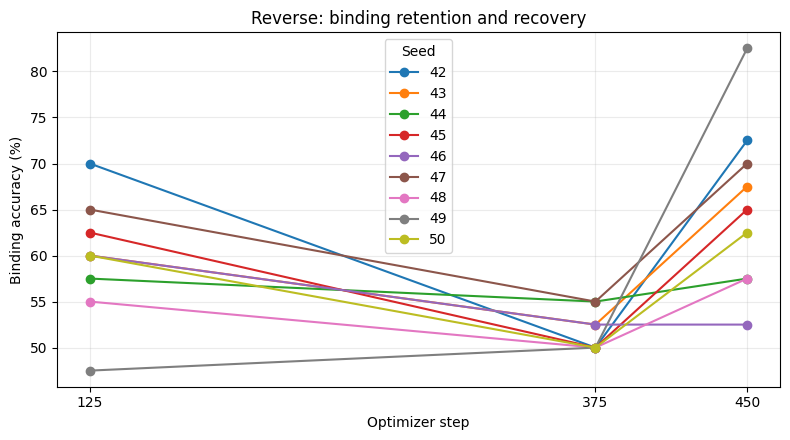

Mean change during attribute-only phase: -8.06 percentage points


In [7]:
interference = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for seed in SEEDS:
    run = RUNS[(seed, "reverse")]
    checkpoints = {snap["step"]: snap["id_dev"]["by_template"]["pair"] * 100 for snap in run["history"]}
    assert all(step in checkpoints for step in (125, 375, 450))
    interference.append({"seed": seed, "after_binding_pct": checkpoints[125],
                         "after_attributes_pct": checkpoints[375], "after_rehearsal_pct": checkpoints[450],
                         "attribute_phase_change_pp": checkpoints[375] - checkpoints[125]})
    ax.plot([125, 375, 450], [checkpoints[125], checkpoints[375], checkpoints[450]], marker="o", label=str(seed))
with (OUTPUT_DIR / "reverse_task_interference.csv").open("w", newline="", encoding="utf-8") as stream:
    writer = csv.DictWriter(stream, fieldnames=list(interference[0]))
    writer.writeheader()
    writer.writerows(interference)
ax.set(xlabel="Optimizer step", ylabel="Binding accuracy (%)", title="Reverse: binding retention and recovery")
ax.set_xticks([125, 375, 450])
ax.legend(title="Seed")
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reverse_binding_retention.png", dpi=180)
plt.show()
print("Mean change during attribute-only phase:", round(statistics.mean(r["attribute_phase_change_pp"] for r in interference), 2), "percentage points")

## Summary

Staged has the highest mean ID-dev binding accuracy over nine seeds (71.94%), versus mixed (69.72%) and reverse (65.28%). Paired confidence intervals include zero, so the study does not demonstrate a reliable final-performance advantage. Reverse training shows interference during the later attribute phase and partial recovery after mixed consolidation. These are development-set findings, not held-out test or OOD evidence.